# Projeto 1 – C11/C111: Travel And Tourism

Análise exploratória do dataset *Travel And Tourism* usando apenas **NumPy, Pandas e Matplotlib**.

As 10 perguntas estão ordenadas da mais para a menos relevante; as 5 primeiras são as da apresentação.

| # | Pergunta |
|---|---|
| 1 | Quais destinos geram mais receita? |
| 2 | Quais são os destinos turísticos mais procurados? |
| 3 | Quais são os principais motivos de cancelamento? |
| 4 | Quantos clientes estão insatisfeitos? |
| 5 | Qual o custo por viajante por noite em cada país? |
| 6 | Em quais meses ocorre o maior volume de viagens e reservas? |
| 7 | Onde se concentram os maiores custos de viagens concluídas? |
| 8 | Quais são os modos de transporte mais utilizados e como variam os custos? |
| 9 | Como gastos e duração variam entre viajantes individuais, duplas e grupos? |
| 10 | Que diferenças existem entre grupos com e sem crianças? |

**Observações sobre os dados**
- `Customer_Rating = 0` significa "sem avaliação" (viagem cancelada ou ainda não realizada); por isso, satisfação só é analisada em viagens concluídas.
- O dataset não informa a moeda dos valores.

## Configuração e carga dos dados

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV_PATH = 'Travel And Tourism.csv'

REVENUE_STATUSES = ['Completed', 'Confirmed']  # reservas que geram receita
RATED_STATUS = 'Completed'                     # só viagens concluídas têm nota
UNHAPPY_THRESHOLD = 3.0
HIGHLIGHT_COUNTRY = 'India'                    # destino de 669 das 1000 reservas
SEASON_YEAR = 2025                             # único ano com reservas e viagens completas

PRIMARY_COLOR = '#2a6f97'
ACCENT_COLOR = '#e07a5f'
NEUTRAL_COLOR = '#9aa5b1'

MESES = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
         'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']

In [2]:
def load_bookings(csv_path: str) -> pd.DataFrame:
    """Lê o CSV, converte as datas e remove reservas duplicadas."""
    dados = pd.read_csv(csv_path, parse_dates=['Booking_Date', 'Travel_Date', 'Return_Date'])
    return dados.drop_duplicates(subset='Booking_ID')


dados = load_bookings(CSV_PATH)

# colunas derivadas usadas em mais de uma pergunta
dados['Custo_por_viajante'] = dados['Total_Trip_Cost'] / dados['Number_of_Travellers']
dados['Custo_viajante_noite'] = dados['Custo_por_viajante'] / dados['Number_of_Nights']

concluidas = dados[dados['Booking_Status'] == RATED_STATUS]

print(f'{dados.shape[0]} reservas, {dados.shape[1]} colunas')
dados.head()

1000 reservas, 31 colunas


,Booking_ID,Booking_Date,Travel_Date,Return_Date,Customer_ID,Customer_Name,Customer_Age,Gender,Customer_City,Customer_Country,...,Booking_Status,Cancellation_Status,Cancellation_Reason,Discount_Amount,Customer_Rating,Customer_Review_Comment,Total_Trip_Cost,Transportation_Type,Custo_por_viajante,Custo_viajante_noite
0,1,2026-02-23,2026-04-18,2026-04-21,cust01,Kenzo Vaughn,18,Male,Dubai,United Arab Emirates,...,Completed,Not Cancelled,Not Applicable,12800,1.0,Poor service experience,115000,Flight,23000.000000,7666.666667
1,2,2025-05-30,2025-06-29,2025-07-02,cust02,Priya Carter,20,Female,Udaipur,India,...,Completed,Not Cancelled,Not Applicable,0,1.5,Poor service experience,56800,Train,14200.000000,4733.333333
2,3,2024-12-30,2025-03-14,2025-03-23,cust03,Elina Vaughn,31,Female,Dubai,United Arab Emirates,...,Completed,Not Cancelled,Not Applicable,74400,2.0,Several arrangements need improvement,669800,Flight,74422.222222,8269.135802
3,4,2026-06-17,2026-09-19,2026-09-26,cust04,Mei Ferraro,30,Male,Kathmandu,Nepal,...,Confirmed,Not Cancelled,Not Applicable,4500,0.0,Not yet travelled,84700,Flight,28233.333333,4033.333333
4,5,2025-03-21,2025-04-21,2025-04-24,cust05,Alina Desai,39,Female,Kuala Lumpur,Malaysia,...,Completed,Not Cancelled,Not Applicable,2800,3.6,Good overall experience,15600,Flight,15600.000000,5200.000000


In [3]:
def _new_axes(title: str, figsize=(10, 6)):
    """Cria uma figura com o estilo padrão do notebook."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)
    return fig, ax


def _label_hbars(ax, bars, labels) -> None:
    """Escreve um rótulo na ponta de cada barra horizontal."""
    for bar, label in zip(bars, labels):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
                f' {label}', va='center', fontsize=9)

## 1. Quais destinos geram mais receita?
Considera reservas concluídas e confirmadas (as que geram receita).

,revenue,share_pct
Destination_City,,
London,19922400,10.4
Malé,17153200,9.0
Paris,16265500,8.5
Dubai,12875400,6.7
Colombo,11991500,6.3
Bali,11794500,6.2
Singapore,10262400,5.4
Bangkok,7130900,3.7
Kathmandu,6778800,3.5


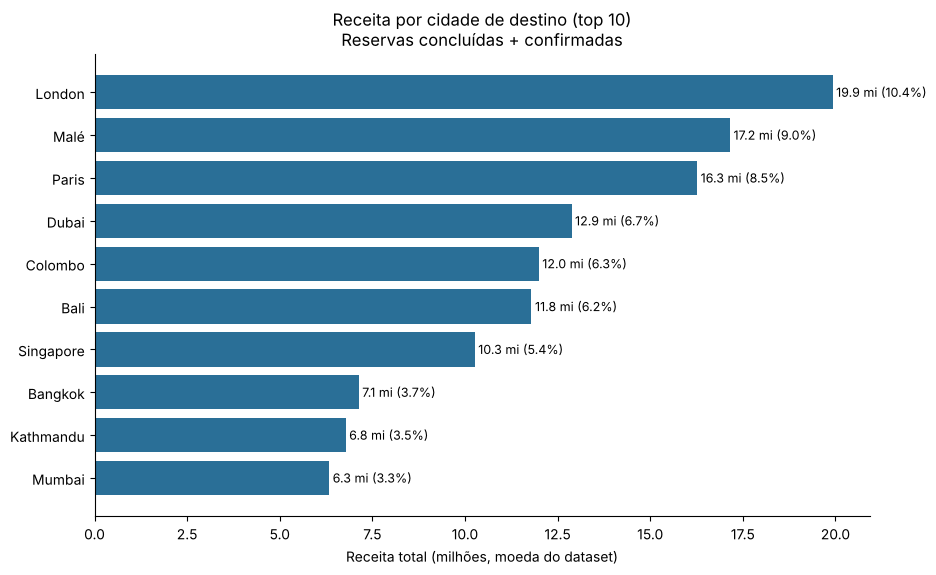

In [4]:
def revenue_by_city(df: pd.DataFrame, top_n: int = 10) -> pd.DataFrame:
    """Receita total e participação (%) das top_n cidades de destino."""
    paid = df[df['Booking_Status'].isin(REVENUE_STATUSES)]
    revenue = paid.groupby('Destination_City')['Total_Trip_Cost'].sum()
    share = 100 * revenue / revenue.sum()
    table = pd.DataFrame({'revenue': revenue, 'share_pct': share})
    return table.nlargest(top_n, 'revenue')


def plot_revenue_by_city(table: pd.DataFrame):
    fig, ax = _new_axes('Receita por cidade de destino (top 10)\n'
                        'Reservas concluídas + confirmadas')
    revenue_mi = table['revenue'] / 1e6
    bars = ax.barh(table.index, revenue_mi, color=PRIMARY_COLOR)
    ax.invert_yaxis()  # maior receita no topo
    _label_hbars(ax, bars, [f'{r:.1f} mi ({s:.1f}%)'
                            for r, s in zip(revenue_mi, table['share_pct'])])
    ax.set_xlabel('Receita total (milhões, moeda do dataset)')
    return fig


receita = revenue_by_city(dados)
display(receita.round(1))
plot_revenue_by_city(receita)
plt.show()

## 2. Quais são os destinos turísticos mais procurados pelos clientes?
Conta todas as reservas (inclusive canceladas), pois medem a procura.

As 11 cidades mais procuradas (top 10 com empates)


,Cidade,Quantidade
0,Colombo,49
1,Shimla,49
2,Rishikesh,45
3,Bali,44
4,Munnar,43
5,Dubai,42
6,Leh,42
7,Manali,42
8,Darjeeling,41
9,London,41


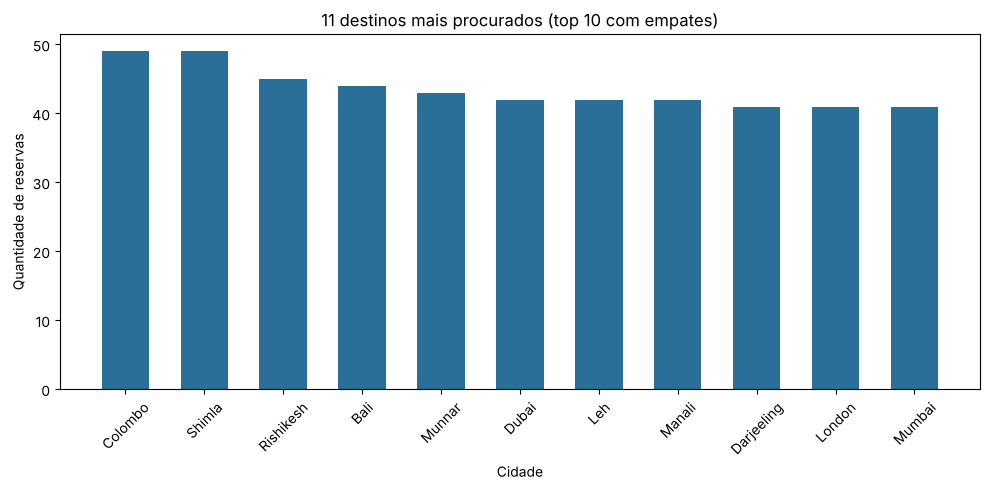

In [5]:
# contando as reservas de cada cidade e selecionando as 10 mais procuradas;
# keep='all' mantém cidades empatadas no corte (London, Darjeeling e Mumbai têm 41)
top_destinos = (dados.groupby('Destination_City')['Booking_ID']
                .count()
                .nlargest(10, keep='all'))

tabela_cidades = pd.DataFrame({'Cidade': top_destinos.index,
                               'Quantidade': top_destinos.values})
print(f'As {len(top_destinos)} cidades mais procuradas (top 10 com empates)')
display(tabela_cidades)

plt.figure(figsize=(10, 5))
plt.bar(top_destinos.index, top_destinos.values, color=PRIMARY_COLOR, width=0.6)
plt.title(f'{len(top_destinos)} destinos mais procurados (top 10 com empates)')
plt.xlabel('Cidade')
plt.ylabel('Quantidade de reservas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Quais são os principais motivos de cancelamento das reservas?

Taxa de cancelamento: 14.1% (141 de 1000 reservas)


,Motivo do cancelamento,Quantidade de cancelamentos
0,Family emergency,27
1,Transportation disruption,24
2,Visa issue,22
3,Budget constraints,21
4,Medical emergency,17
5,Work commitment,16
6,Change in travel plans,14


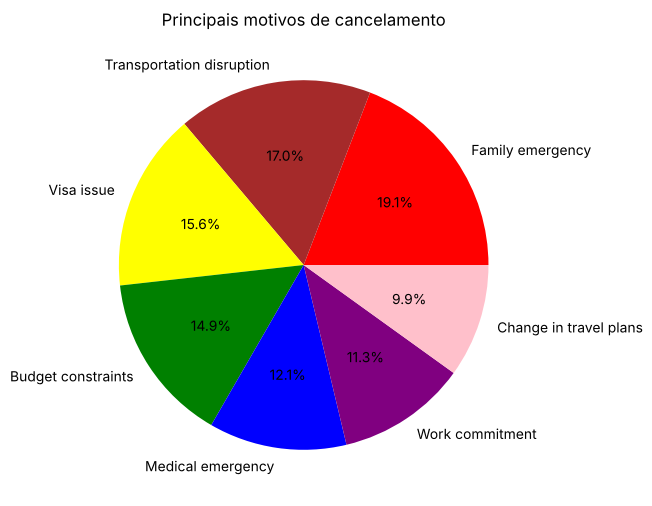

In [6]:
cancelamentos = dados[dados['Cancellation_Status'] == 'Cancelled']

# contando os cancelamentos por motivo, do mais para o menos frequente
qtd_motivos = (cancelamentos.groupby('Cancellation_Reason')['Booking_ID']
               .count()
               .sort_values(ascending=False))

tabela_cancelamento = pd.DataFrame({
    'Motivo do cancelamento': qtd_motivos.index,
    'Quantidade de cancelamentos': qtd_motivos.values,
})
taxa = 100 * len(cancelamentos) / len(dados)
print(f'Taxa de cancelamento: {taxa:.1f}% ({len(cancelamentos)} de {len(dados)} reservas)')
display(tabela_cancelamento)

plt.figure(figsize=(6, 6))
plt.pie(qtd_motivos, labels=qtd_motivos.index, autopct='%1.1f%%',
        colors=['red', 'brown', 'yellow', 'green', 'blue', 'purple', 'pink'])
plt.title('Principais motivos de cancelamento')
plt.show()

## 4. Quantos clientes estão insatisfeitos (nota < 3)?
Apenas viagens concluídas (as únicas com nota).

n=772 | média=3.00 | mediana=2.90 | insatisfeitos=50.3%


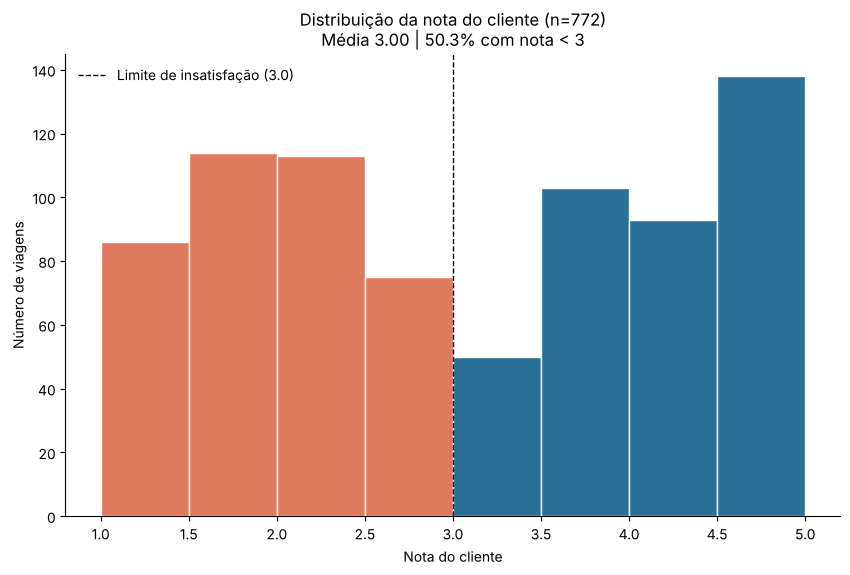

In [7]:
def completed_ratings(df: pd.DataFrame) -> pd.Series:
    """Notas dos clientes em viagens concluídas."""
    return df.loc[df['Booking_Status'].eq(RATED_STATUS), 'Customer_Rating']


def unhappy_share(ratings: pd.Series) -> float:
    """Percentual de notas abaixo do limite de insatisfação."""
    return 100 * ratings.lt(UNHAPPY_THRESHOLD).mean()


def plot_satisfaction(ratings: pd.Series):
    share = unhappy_share(ratings)
    fig, ax = _new_axes(f'Distribuição da nota do cliente (n={len(ratings)})\n'
                        f'Média {ratings.mean():.2f} | {share:.1f}% com nota < 3')
    # notas vão de 1.0 a 5.0 em passos de 0.1; faixas de 0.5 têm o mesmo
    # número de valores possíveis, evitando barras distorcidas
    bins = np.arange(1.0, 5.5, 0.5)
    _, edges, patches = ax.hist(ratings, bins=bins, edgecolor='white')
    for left_edge, patch in zip(edges[:-1], patches):
        patch.set_facecolor(ACCENT_COLOR if left_edge < UNHAPPY_THRESHOLD else PRIMARY_COLOR)
    ax.axvline(UNHAPPY_THRESHOLD, color='black', linestyle='--', linewidth=1,
               label='Limite de insatisfação (3.0)')
    ax.legend(frameon=False)
    ax.set_xlabel('Nota do cliente')
    ax.set_ylabel('Número de viagens')
    return fig


notas = completed_ratings(dados)
print(f'n={len(notas)} | média={notas.mean():.2f} | mediana={notas.median():.2f} | '
      f'insatisfeitos={unhappy_share(notas):.1f}%')
plot_satisfaction(notas)
plt.show()

## 5. Qual o custo médio por viajante por noite em cada país de destino?

,Custo por viajante por noite
Destination_Country,
France,24553.0
United Kingdom,22254.0
Maldives,17546.0
United Arab Emirates,12991.0
Indonesia,11744.0
Singapore,11506.0
Thailand,9062.0
Sri Lanka,8520.0
Nepal,7152.0


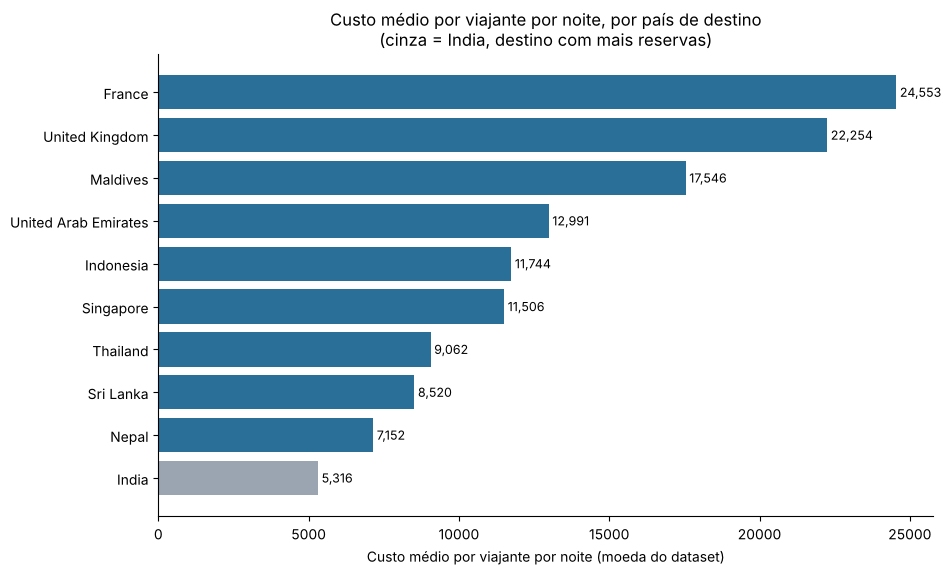

In [8]:
def cost_per_traveller_night(df: pd.DataFrame) -> pd.Series:
    """Custo médio por viajante por noite, por país de destino."""
    return (df.groupby('Destination_Country')['Custo_viajante_noite']
            .mean()
            .sort_values(ascending=False))


def plot_cost_per_night(costs: pd.Series):
    fig, ax = _new_axes('Custo médio por viajante por noite, por país de destino\n'
                        f'(cinza = {HIGHLIGHT_COUNTRY}, destino com mais reservas)')
    colors = np.where(costs.index == HIGHLIGHT_COUNTRY, NEUTRAL_COLOR, PRIMARY_COLOR)
    bars = ax.barh(costs.index, costs.values, color=colors)
    ax.invert_yaxis()
    _label_hbars(ax, bars, [f'{c:,.0f}' for c in costs.values])
    ax.set_xlabel('Custo médio por viajante por noite (moeda do dataset)')
    return fig


custo_noite = cost_per_traveller_night(dados)
display(custo_noite.round(0).to_frame('Custo por viajante por noite'))
plot_cost_per_night(custo_noite)
plt.show()

## 6. Em quais meses ocorre o maior volume de viagens e reservas?

As reservas vão de jan/2024 a ago/2026: somar todos os anos faria jan–ago contarem 3 anos e
set–dez só 2, criando uma falsa queda no fim do ano. Por isso usamos só **2025**, único ano
com reservas e viagens completas nas duas pontas.

,Reservas por mês,Viagens por mês
Janeiro,29,26
Fevereiro,27,28
Março,38,27
Abril,27,27
Maio,32,45
Junho,27,19
Julho,40,36
Agosto,34,37
Setembro,26,30
Outubro,36,31


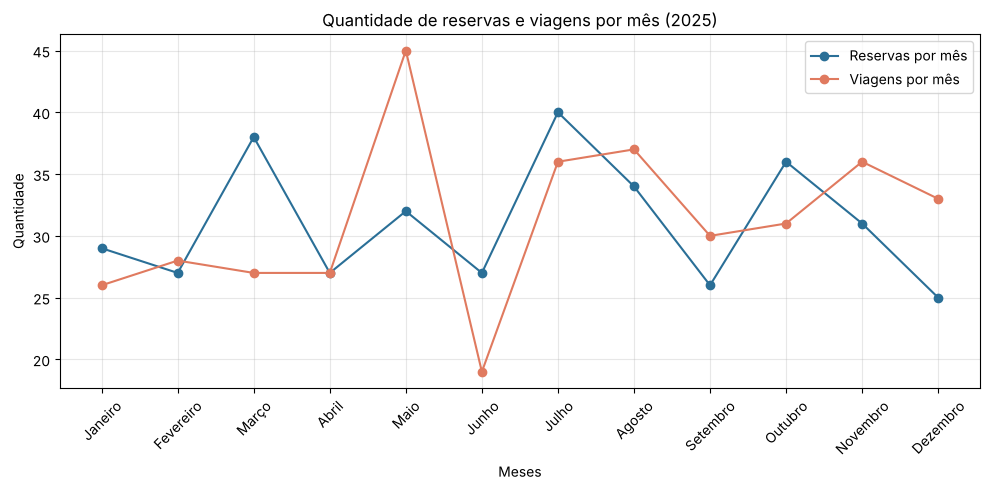

In [9]:
reservas_ano = dados[dados['Booking_Date'].dt.year == SEASON_YEAR]
viagens_ano = dados[dados['Travel_Date'].dt.year == SEASON_YEAR]

# contando reservas e viagens por mês
tabela_meses = pd.DataFrame({
    'Reservas por mês': reservas_ano.groupby(reservas_ano['Booking_Date'].dt.month)['Booking_ID'].count(),
    'Viagens por mês': viagens_ano.groupby(viagens_ano['Travel_Date'].dt.month)['Booking_ID'].count(),
}).reindex(range(1, 13), fill_value=0)  # garante os 12 meses
tabela_meses.index = MESES
display(tabela_meses)

plt.figure(figsize=(10, 5))
plt.plot(tabela_meses.index, tabela_meses['Reservas por mês'],
         color=PRIMARY_COLOR, marker='o', label='Reservas por mês')
plt.plot(tabela_meses.index, tabela_meses['Viagens por mês'],
         color=ACCENT_COLOR, marker='o', label='Viagens por mês')
plt.title(f'Quantidade de reservas e viagens por mês ({SEASON_YEAR})')
plt.xlabel('Meses')
plt.ylabel('Quantidade')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Onde se concentram os maiores custos de viagens concluídas?

,Viagens,Custo_total,Custo_medio
Destination_Country,,,
India,522,70023000,134144.0
Maldives,27,16421100,608189.0
United Kingdom,26,15635400,601362.0
France,20,12642300,632115.0
Sri Lanka,41,11590300,282690.0
United Arab Emirates,29,11108200,383041.0
Indonesia,29,10630900,366583.0
Singapore,21,9563800,455419.0
Thailand,31,7130900,230029.0


Custo total: 169991000


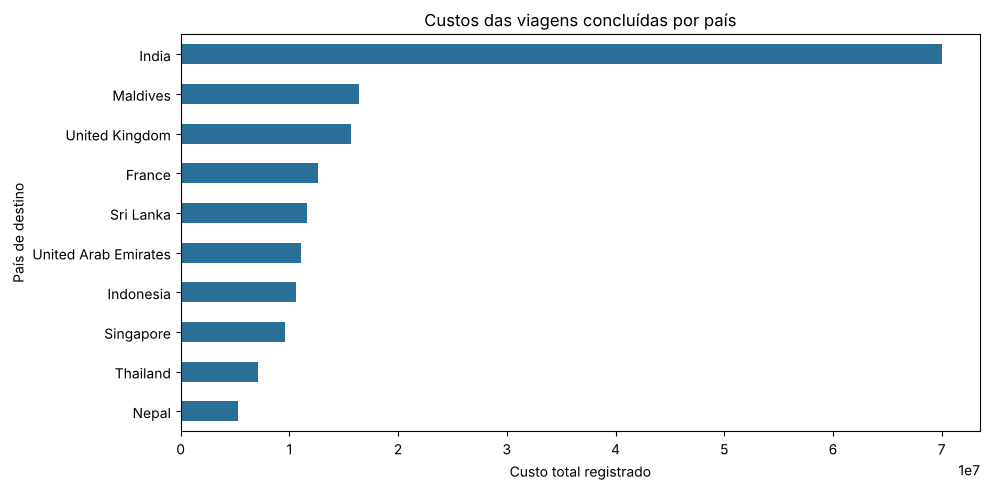

In [10]:
custos = concluidas.groupby('Destination_Country').agg(
    Viagens=('Booking_ID', 'size'),
    Custo_total=('Total_Trip_Cost', 'sum'),
    Custo_medio=('Total_Trip_Cost', 'mean'),
).sort_values('Custo_total', ascending=False)
display(custos.round(0))
print('Custo total:', concluidas['Total_Trip_Cost'].sum())

custos['Custo_total'].sort_values().plot(kind='barh', figsize=(10, 5), color=PRIMARY_COLOR)
plt.title('Custos das viagens concluídas por país')
plt.xlabel('Custo total registrado')
plt.ylabel('País de destino')
plt.tight_layout()
plt.show()

## 8. Quais são os modos de transporte mais utilizados e como variam os custos normalizados entre eles?

,Reservas,Custo_mediano
Transportation_Type,,
Flight,518,38136.11
Train,145,22050.00
Car,109,21637.50


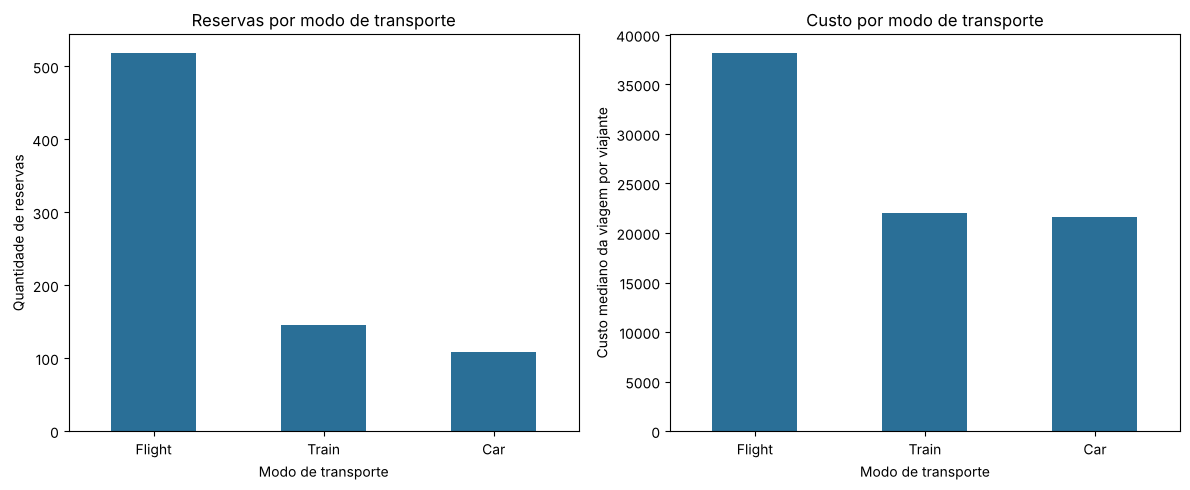

In [11]:
modos = concluidas.groupby('Transportation_Type').agg(
    Reservas=('Booking_ID', 'size'),
    Custo_mediano=('Custo_por_viajante', 'median'),
).sort_values('Reservas', ascending=False)
display(modos.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

modos['Reservas'].plot(kind='bar', color=PRIMARY_COLOR, ax=axes[0], rot=0)
axes[0].set_title('Reservas por modo de transporte')
axes[0].set_xlabel('Modo de transporte')
axes[0].set_ylabel('Quantidade de reservas')

modos['Custo_mediano'].plot(kind='bar', color=PRIMARY_COLOR, ax=axes[1], rot=0)
axes[1].set_title('Custo por modo de transporte')
axes[1].set_xlabel('Modo de transporte')
axes[1].set_ylabel('Custo mediano da viagem por viajante')

plt.tight_layout()
plt.show()

## 9. Como os gastos e a duração das viagens variam entre viajantes individuais, duplas e grupos?

"Dupla" em vez de "Casal": 11 das 156 reservas com 2 viajantes incluem uma criança, então nem toda dupla é um casal.

Comparação entre os perfis de viajantes:


,Reservas,Gasto_medio,Duracao_media
Perfil,,,
Individual,76,58935.53,5.41
Dupla,156,77664.74,5.24
Família/Grupo,768,275057.42,5.40


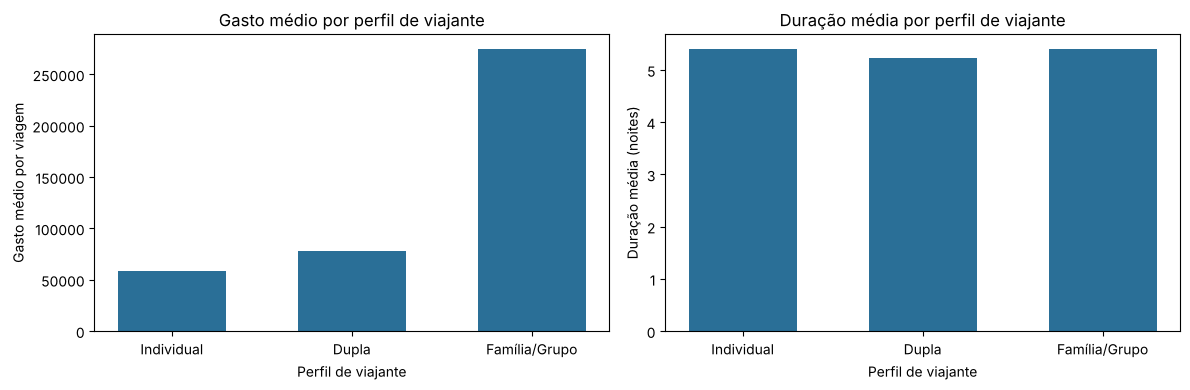

In [12]:
# 1 viajante = Individual, 2 = Dupla, 3 ou mais = Família/Grupo
dados['Perfil'] = pd.cut(dados['Number_of_Travellers'], bins=[0, 1, 2, np.inf],
                         labels=['Individual', 'Dupla', 'Família/Grupo'])

tabela_viajantes = dados.groupby('Perfil', observed=True).agg(
    Reservas=('Booking_ID', 'size'),
    Gasto_medio=('Total_Trip_Cost', 'mean'),
    Duracao_media=('Number_of_Nights', 'mean'),
)
print('Comparação entre os perfis de viajantes:')
display(tabela_viajantes.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(tabela_viajantes.index, tabela_viajantes['Gasto_medio'], color=PRIMARY_COLOR, width=0.6)
axes[0].set_title('Gasto médio por perfil de viajante')
axes[0].set_xlabel('Perfil de viajante')
axes[0].set_ylabel('Gasto médio por viagem')

axes[1].bar(tabela_viajantes.index, tabela_viajantes['Duracao_media'], color=PRIMARY_COLOR, width=0.6)
axes[1].set_title('Duração média por perfil de viajante')
axes[1].set_xlabel('Perfil de viajante')
axes[1].set_ylabel('Duração média (noites)')

plt.tight_layout()
plt.show()

## 10. Que diferenças existem entre grupos com e sem crianças?

,Sem crianças,Com crianças
Reservas,481.00,519.00
Viajantes_medios,3.48,7.68
Custo_total_mediano,98900.00,217100.00
Custo_por_viajante,33450.00,28714.29


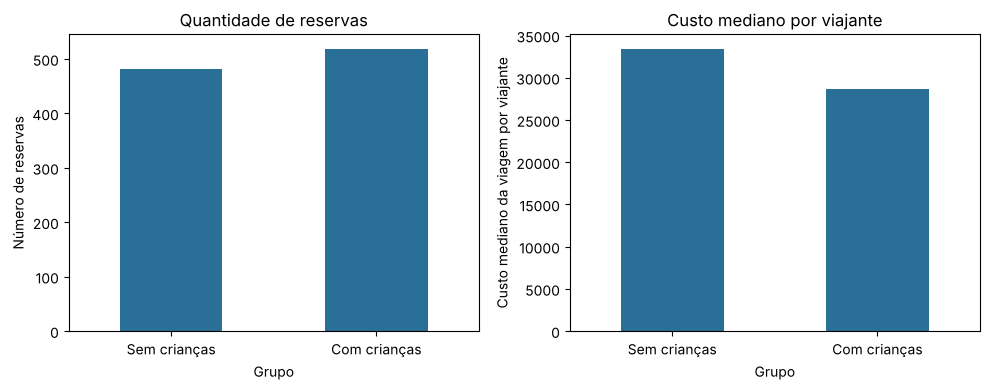

In [13]:
dados['Com_criancas'] = dados['Number_of_Children'] > 0

grupos = dados.groupby('Com_criancas').agg(
    Reservas=('Booking_ID', 'size'),
    Viajantes_medios=('Number_of_Travellers', 'mean'),
    Custo_total_mediano=('Total_Trip_Cost', 'median'),
    Custo_por_viajante=('Custo_por_viajante', 'median'),
).rename(index={False: 'Sem crianças', True: 'Com crianças'})
display(grupos.rename_axis(None).round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

grupos['Reservas'].plot(kind='bar', color=PRIMARY_COLOR, ax=axes[0], rot=0)
axes[0].set_title('Quantidade de reservas')
axes[0].set_xlabel('Grupo')
axes[0].set_ylabel('Número de reservas')

grupos['Custo_por_viajante'].plot(kind='bar', color=PRIMARY_COLOR, ax=axes[1], rot=0)
axes[1].set_title('Custo mediano por viajante')
axes[1].set_xlabel('Grupo')
axes[1].set_ylabel('Custo mediano da viagem por viajante')

plt.tight_layout()
plt.show()